c:\Users\abhis\AppData\Local\Programs\Python\Python310\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
c:\Users\abhis\AppData\Local\Programs\Python\Python310\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


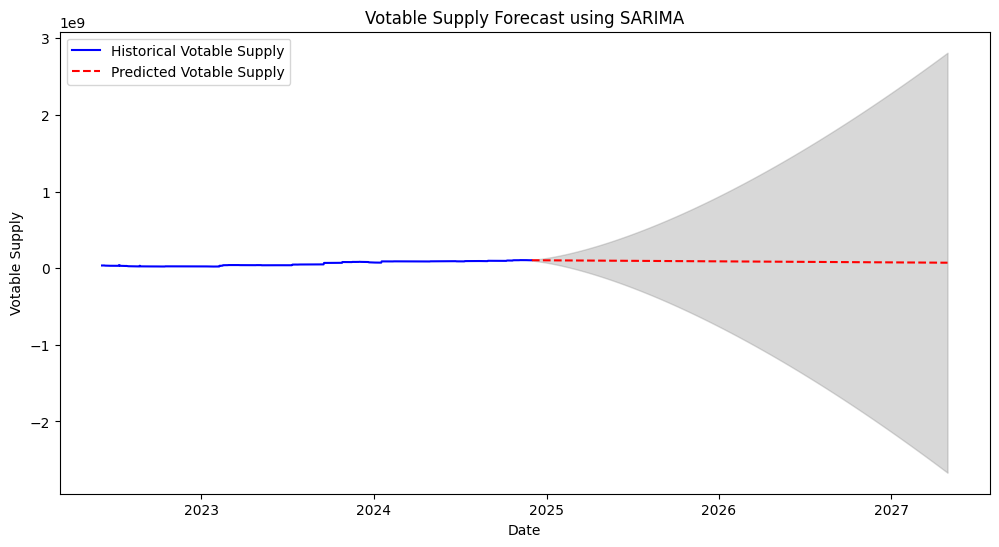

            Predicted Votable Supply  VS_CS Ratio
Date                                             
2024-12-01              1.040984e+08     0.077498
2024-12-02              1.039641e+08     0.077398
2024-12-03              1.041019e+08     0.077501
2024-12-04              1.041185e+08     0.077513
2024-12-05              1.038023e+08     0.077278
...                              ...          ...
2027-04-26              7.181125e+07     0.025393
2027-04-27              7.191353e+07     0.025429
2027-04-28              7.191611e+07     0.025430
2027-04-29              7.157847e+07     0.025311
2027-04-30              7.161683e+07     0.025324

[881 rows x 2 columns]


In [9]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Step 1: Load Historical Data (VS_CS_Data.csv) and Future Circulating Supply Data (Future_CS_Data.csv)
historical_data = pd.read_csv('../../../data/votable_supply-dhruvi/data/pr_raw_data.csv')
future_data = pd.read_csv('../../../data/votable_supply_framework/future_vs_prediction/future_cs_data.csv')

# Step 2: Convert 'Date' column to datetime format
historical_data['Date'] = pd.to_datetime(historical_data['Date'], format='%d-%m-%Y')
future_data['Date'] = pd.to_datetime(future_data['Date'], format='%Y-%m-%d')

# Step 3: Set 'Date' column as the index
historical_data.set_index('Date', inplace=True)
future_data.set_index('Date', inplace=True)

# Step 4: Define the SARIMA model
# The parameters (p, d, q) and (P, D, Q, S) need to be determined (this can be done using grid search or auto_arima)
sarima_model = SARIMAX(
    historical_data['Votable Supply'],  # Dependent variable
    order=(1, 1, 1),  # (p, d, q) for ARIMA
    seasonal_order=(1, 1, 1, 7),  # (P, D, Q, S) for seasonality (7 for weekly seasonality)
    enforce_stationarity=False,
    enforce_invertibility=False
)

# Step 5: Fit the SARIMA model
sarima_result = sarima_model.fit(disp=False)

# Step 6: Make predictions for the future
# Forecast the future values for the Votable Supply
forecast_steps = len(future_data)
forecast = sarima_result.get_forecast(steps=forecast_steps)

# Get the predicted values and confidence intervals
forecast_mean = forecast.predicted_mean
confidence_intervals = forecast.conf_int()

# Step 7: Add predictions to future data
future_data['Predicted Votable Supply'] = forecast_mean

# Step 8: Calculate VS_CS Ratio (Votable Supply / Circulating Supply)
historical_data['VS_CS Ratio'] = historical_data['Votable Supply'] / historical_data['Circulating Supply']
future_data['VS_CS Ratio'] = future_data['Predicted Votable Supply'] / future_data['Circulating Supply']

# Step 9: Combine historical data with future predictions for output
combined_data = pd.concat([historical_data[['Votable Supply', 'VS_CS Ratio']], 
                           future_data[['Predicted Votable Supply', 'VS_CS Ratio']]], axis=0)

# Step 10: Save the combined data to a CSV file
combined_data.to_csv('Votable_Supply_Predictions_with_VS_CS_Ratio.csv')

# Step 11: Plot the results
plt.figure(figsize=(12, 6))
plt.plot(historical_data.index, historical_data['Votable Supply'], label='Historical Votable Supply', color='blue')
plt.plot(future_data.index, future_data['Predicted Votable Supply'], label='Predicted Votable Supply', color='red', linestyle='--')
plt.fill_between(future_data.index, confidence_intervals.iloc[:, 0], confidence_intervals.iloc[:, 1], color='gray', alpha=0.3)
plt.xlabel('Date')
plt.ylabel('Votable Supply')
plt.title('Votable Supply Forecast using SARIMA')
plt.legend()
plt.show()

# Step 12: Evaluate the model (optional, but good practice)
# Here you could evaluate the prediction accuracy if you had test data
# For now, we'll print the forecasted values
print(future_data[['Predicted Votable Supply', 'VS_CS Ratio']])
